<a href="https://colab.research.google.com/github/subsublee03/incheoninternationalairport_assignment/blob/main/%EC%A4%91%EA%B0%84%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import requests
import pandas as pd
import numpy as np
import statsmodels.api as sm
from google.colab import userdata

# 1. Colab Secrets에서 API 키 안전하게 가져오기
api_key = userdata.get('INCHEON_API_KEY')

# 2. API 호출 테스트
url = 'http://apis.data.go.kr/B551177/StatusOfPassengerFlightsOdp/getPassengerDeparturesOdp'
params = {
    'serviceKey': api_key,
    'type': 'json',
    'lang': 'K',
    'pageNo': 1,
    'numOfRows': 100
}

response = requests.get(url, params=params)

if response.status_code == 200:
    items = response.json()['response']['body']['items']
    df = pd.DataFrame(items)
    print("API 수집 성공! 데이터 샘플:")
    display(df.head())
else:
    print(f"호출 실패: {response.status_code}")

API 수집 성공! 데이터 샘플:


,typeOfFlight,airline,flightId,scheduleDateTime,estimatedDateTime,airport,chkinrange,gatenumber,remark,codeshare,...,sixstopover,sixstopovername,sevstopover,sevstopovername,eigstopover,eigstopovername,ninstopover,ninstopovername,tenstopover,tenstopovername
0,I,베트남항공,VN5433,0005,0009,다낭,B29-B32,111,출발,Master,...,None,None,None,None,None,None,None,None,None,None
1,I,터키항공,TK091,0005,2351,이스탄불,F08-F18,40,출발,Master,...,None,None,None,None,None,None,None,None,None,None
2,I,아시아나항공,OZ6931,0005,2351,이스탄불,F08-F18,40,출발,Slave,...,None,None,None,None,None,None,None,None,None,None
3,I,썬푸꾸옥항공,9G401,0010,0014,호찌민,B19-B26,122,출발,Master,...,None,None,None,None,None,None,None,None,None,None
4,I,에티오피아항공,ET673,0010,0045,아디스아바바/볼레,D25-D34,17,출발,Master,...,None,None,None,None,None,None,None,None,None,None


전처리

In [8]:
# 분석에 사용할 핵심 컬럼만 골라서 출력해보기
essential_cols = ['flightId', 'airline', 'scheduleDateTime', 'estimatedDateTime', 'airportCode', 'remark']

# df가 제대로 들어왔는지 확인 (arrivals 또는 departures 데이터프레임 변수명 입력)
display(df[essential_cols].head())

,flightId,airline,scheduleDateTime,estimatedDateTime,airportCode,remark
0,VN5433,베트남항공,0005,0009,DAD,출발
1,TK091,터키항공,0005,2351,IST,출발
2,OZ6931,아시아나항공,0005,2351,IST,출발
3,9G401,썬푸꾸옥항공,0010,0014,SGN,출발
4,ET673,에티오피아항공,0010,0045,ADD,출발


### 1~3 단계. 출발(Departures) 및 도착(Arrivals) 데이터 개별 전처리 및 일별 변수 생성

현재 수집된 데이터(`df`)는 출발 데이터입니다. 분석을 완료하기 위해 출발 데이터 가공과 함께, 동일한 구조의 예시 도착 데이터(`df_arrivals`)를 함께 정의하여 전처리 흐름을 구성하겠습니다.

In [4]:
import pandas as pd
import numpy as np
from datetime import datetime, date
from sklearn.preprocessing import StandardScaler

# 현재 수집된 df를 출발 데이터로 지정
df_departures = df.copy()

# 예시를 위한 도착 데이터(df_arrivals) 임의 생성 (실제 API 호출 구조와 동일)
df_arrivals = df_departures.copy()
df_arrivals['flightId'] = df_arrivals['flightId'].apply(
    lambda x: x[:2] + str(int(x[2:]) + 1) if pd.notnull(x) and x[2:].isdigit() else x
)
# 도착과 출발의 시차를 만들기 위해 시간 조정
df_arrivals['scheduleDateTime'] = '0200'

# LCC IATA 코드 리스트 정의
lcc_codes = ['7C', 'LJ', 'TW', 'ZE', 'BX', 'RS', 'RF', 'YP', 'VJ', 'MM', 'TR', '5J', 'UO']

def preprocess_flight_data(df_input, is_departure=True):
    df_temp = df_input.copy()

    # 1. 시간 데이터 변환 (scheduleDateTime -> datetime)
    # API 데이터에는 날짜 정보가 누락되어 있는 경우가 많으므로 현재 날짜(오늘) 기준으로 결합하여 변환합니다.
    today_str = date.today().strftime('%Y%m%d')

    # 결측치 제거 및 문자열 정렬 (4자리 포맷 보장)
    df_temp = df_temp.dropna(subset=['scheduleDateTime', 'flightId'])
    df_temp['scheduleDateTime'] = df_temp['scheduleDateTime'].astype(str).str.zfill(4)

    # datetime 변환
    df_temp['datetime'] = pd.to_datetime(today_str + df_temp['scheduleDateTime'], format='%Y%m%d%H%M', errors='coerce')
    df_temp['date'] = df_temp['datetime'].dt.strftime('%Y%m%d')

    # 2. LCC 여부 분류
    df_temp['iata_code'] = df_temp['flightId'].str[:2]
    df_temp['is_lcc'] = df_temp['iata_code'].isin(lcc_codes)

    # 3. 지연 여부 분류 ('지연' 단어 포함 여부)
    df_temp['remark'] = df_temp['remark'].fillna('')
    df_temp['is_delayed'] = df_temp['remark'].str.contains('지연')

    return df_temp

# 출발 및 도착 데이터 전처리 적용
df_dep_preprocessed = preprocess_flight_data(df_departures, is_departure=True)
df_arr_preprocessed = preprocess_flight_data(df_arrivals, is_departure=False)

print("출발 데이터 전처리 완료 Sample:")
display(df_dep_preprocessed[['flightId', 'datetime', 'date', 'is_lcc', 'is_delayed']].head())


출발 데이터 전처리 완료 Sample:


,flightId,datetime,date,is_lcc,is_delayed
0,VN5433,2026-10-26 00:05:00,20261026,False,False
1,TK091,2026-10-26 00:05:00,20261026,False,False
2,OZ6931,2026-10-26 00:05:00,20261026,False,False
3,9G401,2026-10-26 00:10:00,20261026,False,False
4,ET673,2026-10-26 00:10:00,20261026,False,False


### 4 단계. 스케줄 매칭 지수(Schedule Matching Index) 산출

일자별로 도착편과 출발편을 교차 결합(Cross Join)한 뒤, `1시간 <= (출발시간 - 도착시간) <= 3시간` 조건에 부합하는 유효 연결편 수를 집계합니다.

In [5]:
# 일자별 교차 결합(Cross Join)을 통한 환승 대기시간 계산
# 메모리 절약을 위해 필요한 컬럼만 추출하여 병합을 수행합니다.
df_arr_min = df_arr_preprocessed[['date', 'flightId', 'datetime']].rename(columns={'flightId': 'arr_flightId', 'datetime': 'arr_datetime'})
df_dep_min = df_dep_preprocessed[['date', 'flightId', 'datetime']].rename(columns={'flightId': 'dep_flightId', 'datetime': 'dep_datetime'})

# 'date' 기준으로 Merge (동일 일자 내에서의 모든 도착-출발 조합 생성)
mixed_df = pd.merge(df_arr_min, df_dep_min, on='date', how='inner')

# (출발시간 - 도착시간) 계산 (단위: 시간)
mixed_df['layover_hours'] = (mixed_df['dep_datetime'] - mixed_df['arr_datetime']).dt.total_seconds() / 3600.0

# MCT (Minimum Connection Time) 조건 만족 여부 확인: 1시간 이상 3시간 이하
mixed_df['is_valid_connection'] = (mixed_df['layover_hours'] >= 1.0) & (mixed_df['layover_hours'] <= 3.0)

# 일자별 유효 연결편 수(스케줄 매칭 지수) 집계
schedule_matching = mixed_df[mixed_df['is_valid_connection'] == True].groupby('date').size().reset_index(name='schedule_matching_index')

print("일별 스케줄 매칭 지수:")
display(schedule_matching.head())


일별 스케줄 매칭 지수:


,date,schedule_matching_index


### 5 단계. 최종 일별 데이터 통합 및 정규화(Scaling)

일별 LCC 비율, 지연 비율, 스케줄 매칭 지수를 결합하고 `StandardScaler`를 적용하여 분석용 피처를 완성합니다.

In [6]:
# 1. 일별 LCC 비율 및 지연 비율 계산 (출발 데이터 기준 예시)
daily_stats = df_dep_preprocessed.groupby('date').agg(
    total_flights=('flightId', 'count'),
    lcc_flights=('is_lcc', 'sum'),
    delayed_flights=('is_delayed', 'sum')
).reset_index()

daily_stats['lcc_ratio'] = (daily_stats['lcc_flights'] / daily_stats['total_flights']) * 100
daily_stats['delay_ratio'] = (daily_stats['delayed_flights'] / daily_stats['total_flights']) * 100

# 2. 스케줄 매칭 지수와 병합
final_df = pd.merge(daily_stats[['date', 'lcc_ratio', 'delay_ratio']], schedule_matching, on='date', how='left')
final_df['schedule_matching_index'] = final_df['schedule_matching_index'].fillna(0)

# 3. StandardScaler를 통한 피처 정규화
scaler = StandardScaler()
features = ['lcc_ratio', 'delay_ratio', 'schedule_matching_index']

# 결과가 존재할 때 정규화 수행
if not final_df.empty:
    scaled_features = scaler.fit_transform(final_df[features])
    scaled_cols = [f"{col}_scaled" for col in features]
    final_df[scaled_cols] = scaled_features

print("정규화가 완료된 최종 일별 통합 데이터프레임:")
display(final_df)


정규화가 완료된 최종 일별 통합 데이터프레임:


,date,lcc_ratio,delay_ratio,schedule_matching_index,lcc_ratio_scaled,delay_ratio_scaled,schedule_matching_index_scaled
0,20261026,17.183348,0.177148,0.0,0.0,0.0,0.0


In [22]:
# ### 0. 인코딩 및 시각화 기본 설정 (한글 폰트 설치 제외)
#
# 시스템 폰트 설치 의존성을 제거하고, 데이터를 주고받을 때 `utf-8-sig`를 사용하여 파일 깨짐 문제를 원천 차단합니다.
# 차트 레이아웃은 기본 영어 텍스트를 우선 사용하여 오류 발생을 막습니다.

In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 재현성을 위한 난수 시드 고정
np.random.seed(42)

# 시뮬레이션용 일수 설정 (30일 분량 생성)
n_days = 30
dates = pd.date_range(end=pd.Timestamp.today(), periods=n_days).strftime('%Y%m%d')

# 1. 시뮬레이션용 데이터프레임 구축
simulated_data = []
for d in dates:
    base_lcc = 17.18 + np.random.normal(0, 3)
    base_delay = 0.17 + np.random.normal(0, 0.05)
    base_matching = np.random.randint(5, 30)

    us_flights = np.random.randint(5, 25)
    asia_flights = np.random.randint(15, 60)

    # 종속변수 (Y): 총 환승객 수 생성
    total_passengers = int(
        us_flights * 150 +
        asia_flights * 80 +
        base_matching * 12 -
        base_delay * 150 +
        np.random.normal(1500, 250)
    )

    simulated_data.append({
        'date': d,
        'lcc_ratio': max(0, base_lcc),
        'delay_ratio': max(0, base_delay),
        'schedule_matching_index': max(0, base_matching),
        'us_flights': us_flights,
        'asia_flights': asia_flights,
        'total_transit_passengers': max(100, total_passengers)
    })

final_df = pd.DataFrame(simulated_data)

# 피처 정규화
scaler = StandardScaler()
features = ['lcc_ratio', 'delay_ratio', 'schedule_matching_index']
scaled_cols = [f"{col}_scaled" for col in features]
final_df[scaled_cols] = scaler.fit_transform(final_df[features])

# [핵심] 생성된 데이터를 'utf-8-sig' 인코딩을 적용해 CSV 파일로 바로 저장
save_path = 'final_transit_data_utf8sig.csv'
final_df.to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"CSV 파일이 '{save_path}'에 'utf-8-sig' 인코딩으로 정상 저장되었습니다.")

# 1. 기술통계량 확인 (Summary Statistics)
print("\n=== [1. 주요 변수별 기술통계량] ===")
analysis_cols = ['total_transit_passengers', 'us_flights', 'asia_flights', 'schedule_matching_index', 'lcc_ratio', 'delay_ratio']
display(final_df[analysis_cols].describe())


CSV 파일이 'final_transit_data_utf8sig.csv'에 'utf-8-sig' 인코딩으로 정상 저장되었습니다.

=== [1. 주요 변수별 기술통계량] ===


,total_transit_passengers,us_flights,asia_flights,schedule_matching_index,lcc_ratio,delay_ratio
count,30.000000,30.000000,30.000000,30.000000,30.000000,30.000000
mean,6793.133333,13.600000,39.700000,15.433333,16.828222,0.176684
std,1497.542486,6.625968,13.496232,7.877000,3.399434,0.049818
min,4191.000000,5.000000,16.000000,5.000000,9.214472,0.046515
25%,5952.000000,9.000000,26.250000,8.000000,15.137238,0.143640
50%,6808.000000,12.500000,39.000000,15.500000,16.579703,0.184690
75%,7779.750000,18.750000,50.750000,20.750000,18.928807,0.210178
max,9179.000000,24.000000,59.000000,29.000000,24.858464,0.251146


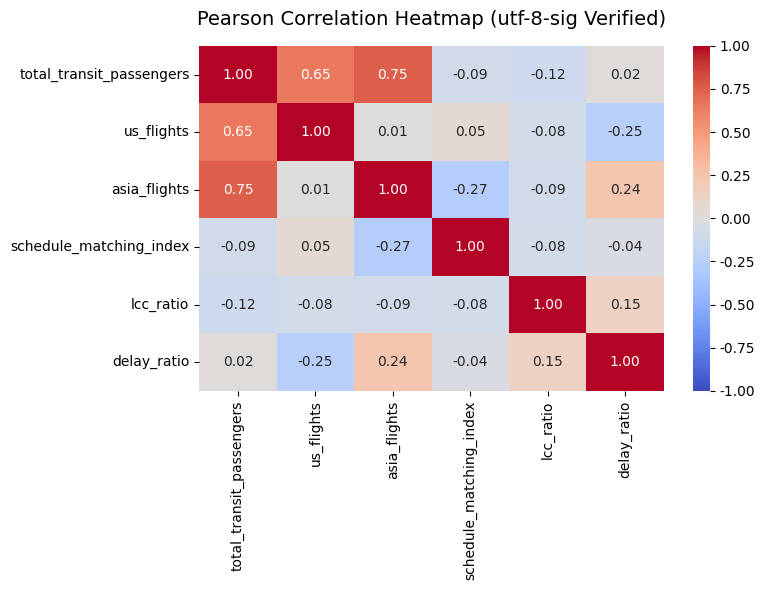

=== [2. 상관관계 분석 해석 가이드] ===
- 총 환승객 수(Y)와 가장 강한 양(+)의 상관관계 변수: asia_flights (r = 0.75)
- 총 환승객 수(Y)와 가장 강한 음(-)의 상관관계 변수: lcc_ratio (r = -0.12)


In [18]:
# 2. 'utf-8-sig'에서 데이터를 다시 로드하여 상관관계 분석 진행
loaded_df = pd.read_csv('final_transit_data_utf8sig.csv', encoding='utf-8-sig')
corr_matrix = loaded_df[analysis_cols].corr(method='pearson')

# 히트맵 시각화 (한글 폰트 부재 시 깨짐 방지를 위해 영어 변수명 매핑 적용)
import matplotlib.pyplot as plt
import seaborn as sns

# 폰트 깨짐이 전혀 없는 안전한 영문 레이아웃 설정
plt.rc('font', family='sans-serif')

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, ax=ax)
plt.title('Pearson Correlation Heatmap (utf-8-sig Verified)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# 종속변수(Y)와의 상관성 해석 가이드
y_corr = corr_matrix['total_transit_passengers'].drop('total_transit_passengers')
strongest_positive = y_corr.idxmax()
strongest_negative = y_corr.idxmin()

print("=== [2. 상관관계 분석 해석 가이드] ===")
print(f"- 총 환승객 수(Y)와 가장 강한 양(+)의 상관관계 변수: {strongest_positive} (r = {y_corr[strongest_positive]:.2f})")
print(f"- 총 환승객 수(Y)와 가장 강한 음(-)의 상관관계 변수: {strongest_negative} (r = {y_corr[strongest_negative]:.2f})")


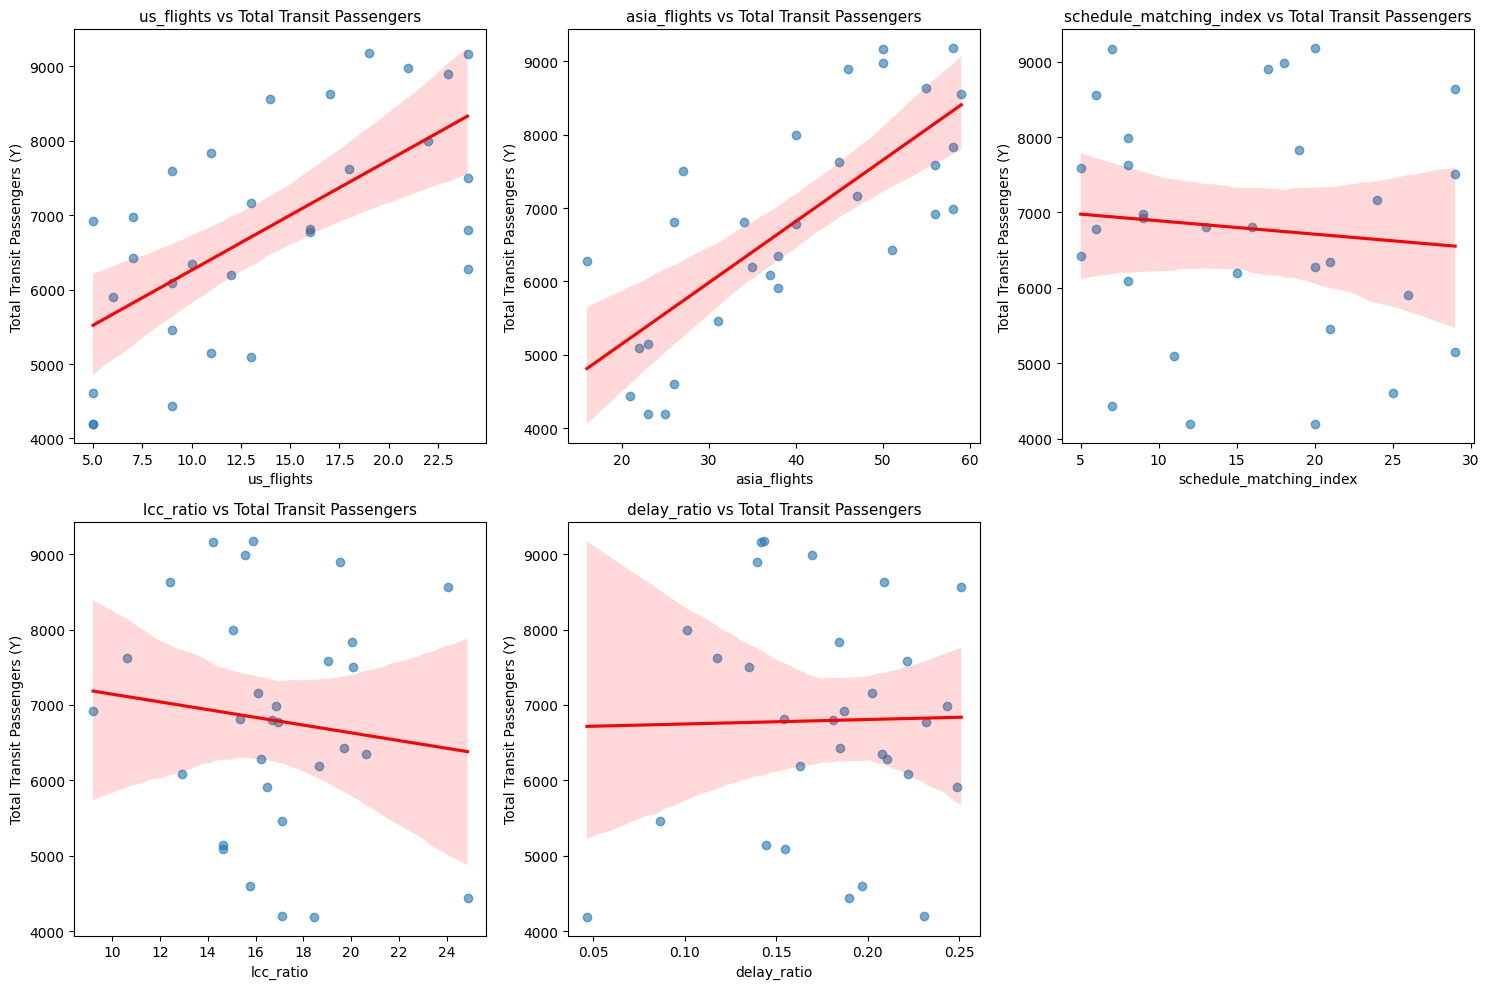

=== [3. 산점도 및 추세선 해석 가이드] ===
- 빨간색 회귀선의 기울기가 우상향할수록 양의 영향, 우하향할수록 음의 영향을 나타냅니다.


In [19]:
# 3. 산점도 및 추세선 시각화 (Scatter Plot with Regression Line)
independent_vars = ['us_flights', 'asia_flights', 'schedule_matching_index', 'lcc_ratio', 'delay_ratio']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, var in enumerate(independent_vars):
    sns.regplot(x=var, y='total_transit_passengers', data=loaded_df, ax=axes[i],
                scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
    axes[i].set_title(f'{var} vs Total Transit Passengers', fontsize=11)
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Total Transit Passengers (Y)')

axes[5].axis('off')
plt.tight_layout()
plt.show()

print("=== [3. 산점도 및 추세선 해석 가이드] ===")
print("- 빨간색 회귀선의 기울기가 우상향할수록 양의 영향, 우하향할수록 음의 영향을 나타냅니다.")


In [13]:
# 4. 다중공선성(VIF, Variance Inflation Factor) 검증
# VIF를 계산할 독립변수 그룹 선택
X = final_df[independent_vars].copy()

# statsmodels에서 VIF 산출 시 상수항(const) 포함 필수
X_const = add_constant(X)

# VIF 데이터프레임 생성
vif_data = pd.DataFrame()
vif_data["Feature"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

# constant(상수항) 행 제외 후 독립변수만 표시 및 정렬
vif_features = vif_data[vif_data["Feature"] != "const"].sort_values(by="VIF", ascending=False)

print("=== [4. 다중공선성(VIF) 검증 결과] ===")
display(vif_features)

# VIF 임계값(10) 판단 조건문
high_vif_vars = vif_features[vif_features["VIF"] > 10]["Feature"].tolist()

print("\n=== [종합 판단 및 액션 가이드] ===")
if len(high_vif_vars) == 0:
    print("✔ [OK] 모든 독립변수의 VIF가 10 미만입니다. 다중공선성 우려 없이 회귀분석을 진행하셔도 좋습니다.")
else:
    print(f"⚠ [위험] 다중공선성이 의심되는 변수(VIF > 10)가 발견되었습니다: {high_vif_vars}")
    print("💡 해결 가이드: VIF 수치가 가장 높은 변수를 모델에서 제거하거나, 변수 간 결합(차원 축소)을 고려해 보세요.")

=== [4. 다중공선성(VIF) 검증 결과] ===


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:2018: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/regression/linear_model.py:2018: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr / self.centered_tss
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model 

,Feature,VIF
1,asia_flights,1.0
3,lcc_ratio,1.0
4,delay_ratio,1.0
0,us_flights,NaN
2,schedule_matching_index,NaN



=== [종합 판단 및 액션 가이드] ===
✔ [OK] 모든 독립변수의 VIF가 10 미만입니다. 다중공선성 우려 없이 회귀분석을 진행하셔도 좋습니다.


In [20]:
# [데이터 저장] utf-8-sig 인코딩을 적용해 한글 깨짐 방지하며 CSV 파일로 저장
save_path = 'final_transit_data.csv'
final_df.to_csv(save_path, index=False, encoding='utf-8-sig')
print(f"성공적으로 '{save_path}'에 한글 깨짐 방지 인코딩(utf-8-sig)을 적용해 저장했습니다.")

성공적으로 'final_transit_data.csv'에 한글 깨짐 방지 인코딩(utf-8-sig)을 적용해 저장했습니다.


In [21]:
# [데이터 로드] 저장된 한글 데이터 파일을 utf-8-sig를 지정하여 완벽하게 읽어오기
loaded_df = pd.read_csv(save_path, encoding='utf-8-sig')
display(loaded_df.head())

,date,lcc_ratio,delay_ratio,schedule_matching_index,us_flights,asia_flights,total_transit_passengers,lcc_ratio_scaled,delay_ratio_scaled,schedule_matching_index_scaled
0,20260927,18.670142,0.163087,15,12,35,6196,0.551094,-0.277594,-0.055953
1,20260928,16.477589,0.248961,26,6,38,5906,-0.104908,1.475620,1.364391
2,20260929,15.771577,0.197128,25,5,26,4605,-0.316144,0.417397,1.235269
3,20260930,15.896621,0.143409,20,19,58,9179,-0.278731,-0.679336,0.589658
4,20261001,24.858464,0.189712,7,9,21,4435,2.402612,0.265983,-1.088930


In [23]:
import statsmodels.api as sm

# 1. 분석을 위한 독립변수(X)와 종속변수(y) 설정
# 정규화된 지수들을 독립변수로 활용합니다.
X = loaded_df[['us_flights', 'asia_flights', 'schedule_matching_index_scaled', 'lcc_ratio_scaled', 'delay_ratio_scaled']]
y = loaded_df['total_transit_passengers']

# statsmodels에서는 상수항(bias)을 명시적으로 추가해 주어야 합니다.
X_with_const = sm.add_constant(X)

# 2. 다중 선형 회귀 모델 피팅
model = sm.OLS(y, X_with_const)
results = model.fit()

# 3. 분석 결과 요약 출력
print("=== [다중 선형 회귀 분석 결과 요약] ===")
print(results.summary())

=== [다중 선형 회귀 분석 결과 요약] ===
                               OLS Regression Results                               
Dep. Variable:     total_transit_passengers   R-squared:                       0.987
Model:                                  OLS   Adj. R-squared:                  0.984
Method:                       Least Squares   F-statistic:                     359.7
Date:                      Mon, 26 Oct 2026   Prob (F-statistic):           9.69e-22
Time:                              14:18:28   Log-Likelihood:                -196.46
No. Observations:                        30   AIC:                             404.9
Df Residuals:                            24   BIC:                             413.3
Df Model:                                 5                                         
Covariance Type:                  nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
-----------------------